# Image inference

Turn an image into instance and class masks, then view them side by side.
An instance label identifies one object; a class label describes its category.

This notebook uses synthetic pixels and random weights to demonstrate the steps
without downloading a checkpoint. Its masks have no biological meaning. For your
own image and pretrained weights, follow the [quick start](../quickstart.md), then
use the plotting and saving steps below. Use the preprocessing and class mapping
specified for your checkpoint.

The notebook uses a CUDA GPU when available and otherwise uses CPU.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from skimage.color import label2rgb

from cellseg_models_pytorch.inference.post_processor import PostProcessor
from cellseg_models_pytorch.models.cellpose import CellPose
from cellseg_models_pytorch.transforms.functional.normalization import minmax_normalize

# Fix the seed so the small demonstration can be repeated.
torch.manual_seed(0)
torch.set_num_threads(2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# Use a 64-pixel example; real image dimensions must be divisible by 32.
image = np.random.default_rng(0).integers(0, 256, (64, 64, 3), dtype=np.uint8)
image = minmax_normalize(image, copy=True)

Device: cuda


In [2]:
# Disable pretrained encoder downloads for this random-weight demonstration.
model = CellPose(3, enc_name="resnet18", enc_pretrain=False, device=device)
model.set_inference_mode(mixed_precision=False)
model.post_processor = PostProcessor("cellpose", {"use_gpu": device.type == "cuda"})

# Prediction produces dense maps; post-processing reconstructs individual objects.
prediction = model.predict(image)
result = model.post_process(prediction, use_async_postproc=False)
instances, classes = result["nuc"][0]

print("Instance count:", len(np.unique(instances[instances > 0])))

Instance count: 15


`predict` accepts HWC NumPy/PIL images or BCHW tensors; normalization is your
responsibility. Dense outputs precede model-specific reconstruction. `nuc` contains
one `(instance_mask, type_mask)` pair per image. `cyto` and `tissue` are `None`
for this nuclei-only model. In the instance mask, 0 is background and each positive
number identifies one object. The type mask gives each object a class number;
class 0 can also be assigned to an object.

For larger images, `predict(..., use_sliding_win=True, window_size=(256, 256),
stride=128)` uses tiled prediction. Window and stride choices must fit the encoder;
whole-slide reading, merging and mixed-precision inference are separate workflows.


## View the masks

The first panel shows the image. The second gives each instance a colour, and
the third gives objects of the same class the same colour. Background is black.
The colours only display label numbers; use your checkpoint's class mapping to
interpret them.

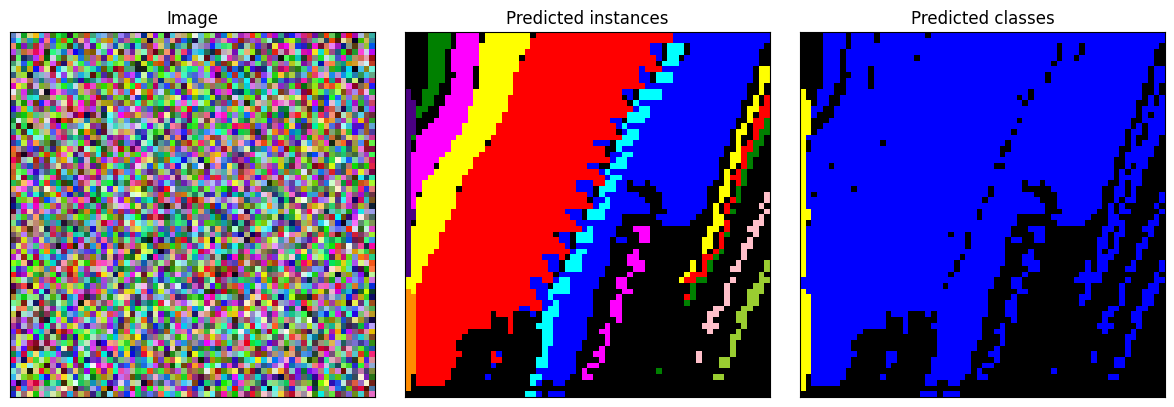

In [3]:
instance_colors = label2rgb(instances, bg_label=0)

# Class 0 can describe an object, so use the instance mask to find background.
class_colors = label2rgb(classes, bg_label=-1)
class_colors[instances == 0] = 0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set(title="Image", xticks=[], yticks=[])

axes[1].imshow(instance_colors)
axes[1].set(title="Predicted instances", xticks=[], yticks=[])

axes[2].imshow(class_colors)
axes[2].set(title="Predicted classes", xticks=[], yticks=[])

fig.tight_layout()
plt.show()

## Save the masks

Choose a new output file so an existing result is not overwritten.

In [4]:
# Preserve labels without lossy image conversion; do not overwrite an existing result.
output_path = Path("segmentation.npz")

# Uncomment to save after choosing a destination:
# with output_path.open("xb") as output:
#     np.savez_compressed(output, instances=instances, classes=classes)